# OSM decomposition

This notebook splits every footprint of the OSM working set into thermal zones and every zone into convex parts. It starts from the table `OSM_1_Preprocessing.ipynb` writes, zones each footprint with the corner-ray perimeter, decomposes every zone with the shared convex-decomposition engine, checks that no area is lost, and exports every convex part with the building and zone it belongs to and the kind of each of its walls.

**Source credit**: the footprints are derived from OpenStreetMap contributors data (ODbL 1.0); `ConvexDecomp` contributes the workflow and the decomposition code, not the footprint data.

**Input**: `subset_buildings_gdf.pkl` of the set chosen with `OSM_DATASET`: `data/bem4ai/` (the BEM4AI sample, written by `OSM_1_Preprocessing.ipynb`) or `data/osm/` (the bundled OSM set of the EG-ICE 2026 paper, written by `OSM_1_Preprocessing.ipynb` at tag `EG-ICE-2026`). Both tables are written locally; the footprint sample `OSM_1_Preprocessing.ipynb` reads ships with the repository.

**Workflow**
1. Corner-ray perimeter: perimeter zones along the facades and core parts (`convexdecomp.corner_perimeter`).
2. Decomposition inputs: one polygon per zone and core part, with its role.
3. Convex decomposition: every polygon cut into convex parts by a bounded beam search (`convexdecomp.osm.decompose`); a zone the search cannot cut is merged with a neighbouring zone.
4. Checks and diagnostics: area kept at every stage, success, failures, small zones and runtime.
5. Zone provenance: every convex part with its building and zone, and every wall classified.

**Runtime**: about 12 minutes for the 990 footprints of the BEM4AI sample on a laptop, most of it in the convex decomposition and its merge fallback.

**Main outputs**
- `buildings_convex_gdf`: one row per building with its zones, its convex parts (`convex_parts_geom`) and the diagnostics
- `polygon_results_gdf`: one row per decomposed polygon (zone, core part, merged zone or whole footprint)
- `osm_zones.gpkg` in the data folder: layer `zones` (one row per convex part) and layer `interfaces` (one row per wall segment)

## Setup

### Configure the notebook
Puts this checkout's `src/` first on `sys.path`, draws figures inline and chooses the footprint set with `OSM_DATASET` (`'bem4ai_sample'` or `'paper'`).

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
from IPython import get_ipython

from shapely.geometry import MultiPolygon, Polygon
from shapely.geometry.base import BaseGeometry

ip = get_ipython()
if ip is not None:
    ip.run_line_magic('matplotlib', 'inline')

# This checkout's src/ goes first on the path, before anything from convexdecomp is imported,
# so that a worktree runs its own code.
_checkout = next(path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (path / 'src' / 'convexdecomp').is_dir())
if str(_checkout / 'src') not in sys.path:
    sys.path.insert(0, str(_checkout / 'src'))

from convexdecomp.notebook_utils import find_project_root

PROJECT_ROOT = find_project_root(Path.cwd().resolve())

# 'bem4ai_sample': the BEM4AI footprint sample of OSM_1; 'paper': the bundled OSM set of the EG-ICE 2026 paper.
OSM_DATASET = 'bem4ai_sample'
OSM_DATA_DIR = {'paper': PROJECT_ROOT / 'data' / 'osm', 'bem4ai_sample': PROJECT_ROOT / 'data' / 'bem4ai'}[OSM_DATASET]
SUBSET_BUILDINGS_PATH = OSM_DATA_DIR / 'subset_buildings_gdf.pkl'

from convexdecomp.plotting.geometry_grid import GHSL_gridplot
from convexdecomp.plotting.polygons import fill_polygon_geometry, set_geometry_frame
from convexdecomp.core.search import AdaptiveSearchConfig
from convexdecomp.osm.decompose import ConvexDecompositionConfig
from convexdecomp.osm.diagnostics import (
    annotate_polygon_failure_reasons,
    parts_from_geom,
    prepare_decomposition_inputs,
    run_building_decomposition,
    select_complexity_ids,
    summarize_building_decomposition,
)
from convexdecomp.corner_perimeter import CornerRayConfig
from convexdecomp.osm.perimeter_zones import build_corner_perimeter_for_gdf, summarize_corner_perimeter

plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['axes.titlesize'] = 10

### Load the working set and inspect it

**Inputs**: `SUBSET_BUILDINGS_PATH`, one row per footprint with `sample_id`, `geometry` (local metres), `area_m2`, `n_vertices` and `n_holes`.

**Steps**
1. Load `subset_buildings_gdf`.
2. Report how many footprints the set holds and how many are not convex (`concave` in the summary).
3. Count the footprints with a polygon smaller than 2 m², the smallest piece the decomposition keeps.
4. Plot the distributions of polygon area, exterior vertices, polygons and holes per footprint, and the smallest polygon area per footprint.

**Outputs**: `subset_buildings_gdf`, printed diagnostics and one row of plots.

**Used functions**: `plot_osm_input_dataset_diagnostics`

subset_buildings_gdf shape: (990, 5)
columns: ['sample_id', 'geometry', 'area_m2', 'n_vertices', 'n_holes']

=== OSM input diagnostics ===
Samples in working set: 990
Polygons across all samples: 990
Concave polygons before convex decomposition: 601 / 990 (60.7%)
Samples with at least one polygon below 2.0 m^2: 0 / 990 (0.0%)


,sample_id,geometry,area_m2,n_vertices,n_holes
0,osm_0001,"POLYGON ((-12.41605 16.6122, -21.49154 -11.819...",798.976977,8,0
1,osm_0002,"POLYGON ((12.28994 6.32204, -11.59102 7.25023,...",322.645924,4,0
2,osm_0003,"POLYGON ((-0.82384 8.03956, -3.24963 7.81827, ...",65.678814,6,0
3,osm_0004,"POLYGON ((-1.88387 12.23407, -11.32992 1.2022,...",279.231285,6,0
4,osm_0005,"POLYGON ((6.55719 1.47794, -1.59178 5.79687, -...",74.684207,4,0


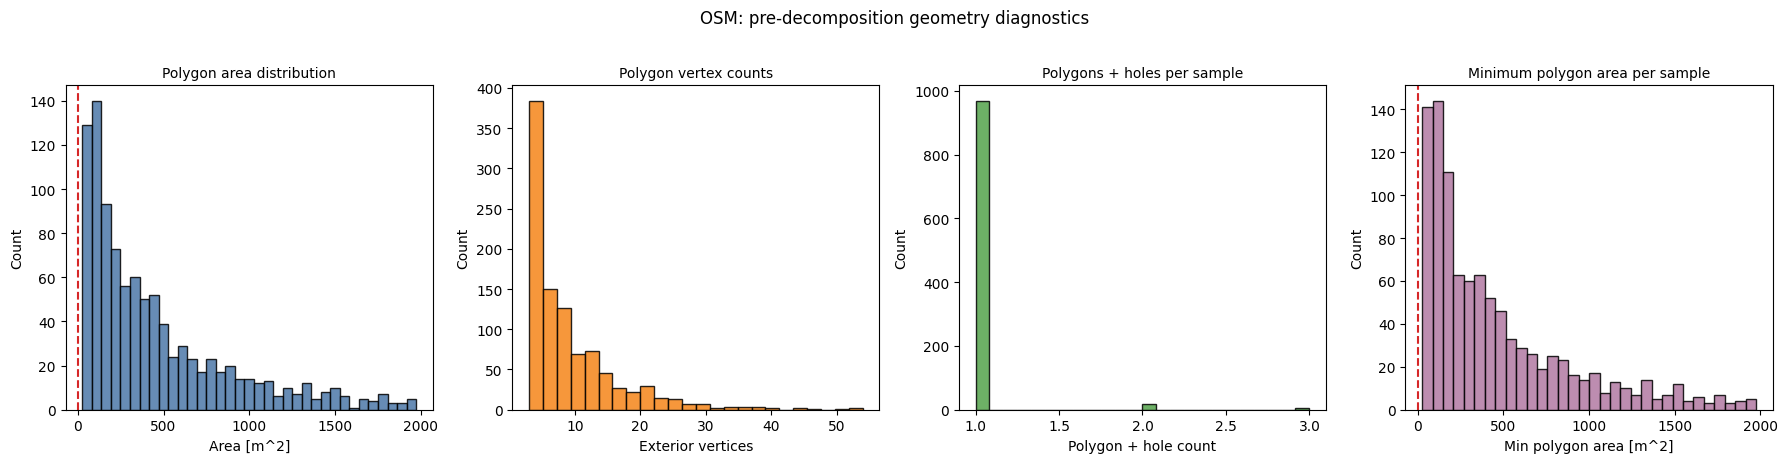

In [2]:
if not SUBSET_BUILDINGS_PATH.exists():
    raise FileNotFoundError(
        f'Missing {SUBSET_BUILDINGS_PATH}. Run OSM_1_Preprocessing.ipynb first to create the preprocessed subset.'
    )

subset_buildings_gdf = pd.read_pickle(SUBSET_BUILDINGS_PATH)

from convexdecomp.diagnostics.datasets import (
    plot_osm_input_dataset_diagnostics,
)

print('subset_buildings_gdf shape:', subset_buildings_gdf.shape)
print('columns:', subset_buildings_gdf.columns.tolist())
print('')
input_diag_summary, input_diag_df = plot_osm_input_dataset_diagnostics(
    subset_buildings_gdf,
    polygons_col='geometry',
    sample_id_col='sample_id',
    min_area_m2=2.0,
    dataset_label='OSM',
)
subset_buildings_gdf.head()

## Zone the footprints with the corner-ray perimeter

Building energy models usually split a floor into perimeter zones along the facades, where gains and losses through the envelope dominate, and a core. The corner-ray perimeter does this for any outline, without moving the outline:

- **Band and rays**: a band 4.5 m deep runs along all facades (about the 15 ft perimeter depth of ASHRAE 90.1 Appendix G). Every corner casts a ray into the building along the bisector of its angle; a ray stops at the inner line of the band or at the first ray it meets. Rays and band line split the band into perimeter zones; what lies inside the band line is the core.
- **Fewer rays where they would cut strips**: the two corners at the end of a wing narrower than 4 m cast no ray, a wall shorter than 1.5 m between two corners casts one ray instead of two, and the corners inside a small bay cast none.
- **Clean-up rules**: rays that meet merge; opposite rays closer than 1 m become one line; rays from convex corners that reach nothing are dropped; core narrower than 1.2 m becomes a line; points closer than 0.5 m merge; narrow zones give way to a diagonal; zones narrower than 2 m merge with their neighbours; corners sharper than 20° are cut off; zones under 0.5 m² join a neighbour; a final tidy step snaps, straightens and splits zone corners.
- **Result**: perimeter zones (role `perimeter_zone`, or `thin_zone` for one that stays narrower than 2 m) and zero or more core parts (role `interior`). A zone may still be non-convex; the convex decomposition cuts it next. A footprint too narrow for a core consists of perimeter zones only.

`src/convexdecomp/corner_perimeter/README.md` shows every step with figures.

### Configure the corner-ray perimeter
`PERIMETER_CFG = CornerRayConfig()` holds the chosen settings; pass a field to change one, for example `CornerRayConfig(band_m=4.0)`, and `settings_table()` lists every setting with its unit and range.

In [3]:
PERIMETER_CFG = CornerRayConfig()

PERIMETER_CFG

CornerRayConfig(band_m=4.5, tie_m=0.1, min_turn_deg=1.0, wing_end_max_m=4.0, wing_end_parallel_deg=30.0, wing_end_long_sides=False, wing_end_check=True, short_wall_one_ray=True, short_wall_m=1.5, short_wall_chamfers=True, short_wall_midpoint=True, short_wall_to_band=True, short_wall_tooth=True, bays=True, bay_width_band=2.5, bay_depth_band=1.2, bay_edge_deg=45.0, bay_min_corners=2.0, bay_wiggle_deg=5.0, bays_in_band=True, bay_check=True, opposite_gap_m=1.0, opposite_angle_deg=20.0, keep_reflex_rays=True, recast_discarded=False, leg_width_m=2.0, leg_angle_deg=15.0, fill_notches=True, notch_passage_m=1.0, narrow_core_m=1.2, collapse_narrow_parts=True, similar_sides_ratio=0.9, close_points_m=0.5, corner_group_m=1.2, corner_group_span_m=2.0, narrow_zone_m=2.0, min_zone_width_m=2.0, relink_m=4.0, sharp_corner_deg=20.0, sharp_keep_convex=False, repeat_thin_after_sharp=True, hull_keeps_width=True, join_specks=True, speck_m2=0.5, repeat_until_stable=True, snap_to_outline=True, merge_close_agai

### Build the perimeter zones and inspect examples

**Inputs**
- `subset_buildings_gdf` with the footprints in `geometry`
- `PERIMETER_CFG`

**Steps**
1. Run the corner-ray perimeter on every footprint.
2. Store the perimeter zones (`perimeter_parts`, with their roles in `perimeter_part_roles`), the core parts (`interior_geom`) and their counts on `subset_buildings_gdf`; a footprint the procedure cannot zone keeps `perimeter_defined = False` and is decomposed whole.
3. Report how many buildings have perimeter zones and a core or perimeter zones only, and how many zones are thinner than 2 m or not convex.
4. Plot the outcome counts and the number of perimeter zones per building.
5. Draw the zones of buildings across the range of zone counts: perimeter zones blue, zones thinner than 2 m red, core parts grey.

**Outputs**
- `subset_buildings_gdf` with the perimeter columns
- `perimeter_summary` with building and zone counts
- Two plots and one grid of example buildings

**Used functions**: `build_corner_perimeter_for_gdf`, `summarize_corner_perimeter`, `GHSL_gridplot`

Corner-ray perimeter summary:
Total buildings: 990
Perimeter zones + core: 626
Perimeter zones only: 364
Perimeter failed (decomposed whole): 0
Perimeter zones: 7338, core parts: 689
Zones thinner than 2 m: 107 in 81 buildings
Zones not convex: 371 in 243 buildings
Time: 42.9 s in total, at most 2.19 s for one building


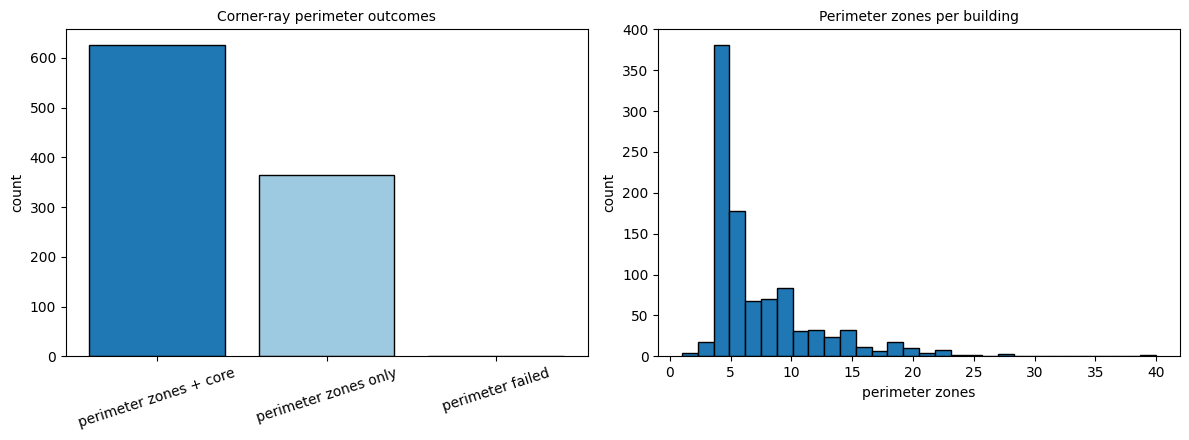

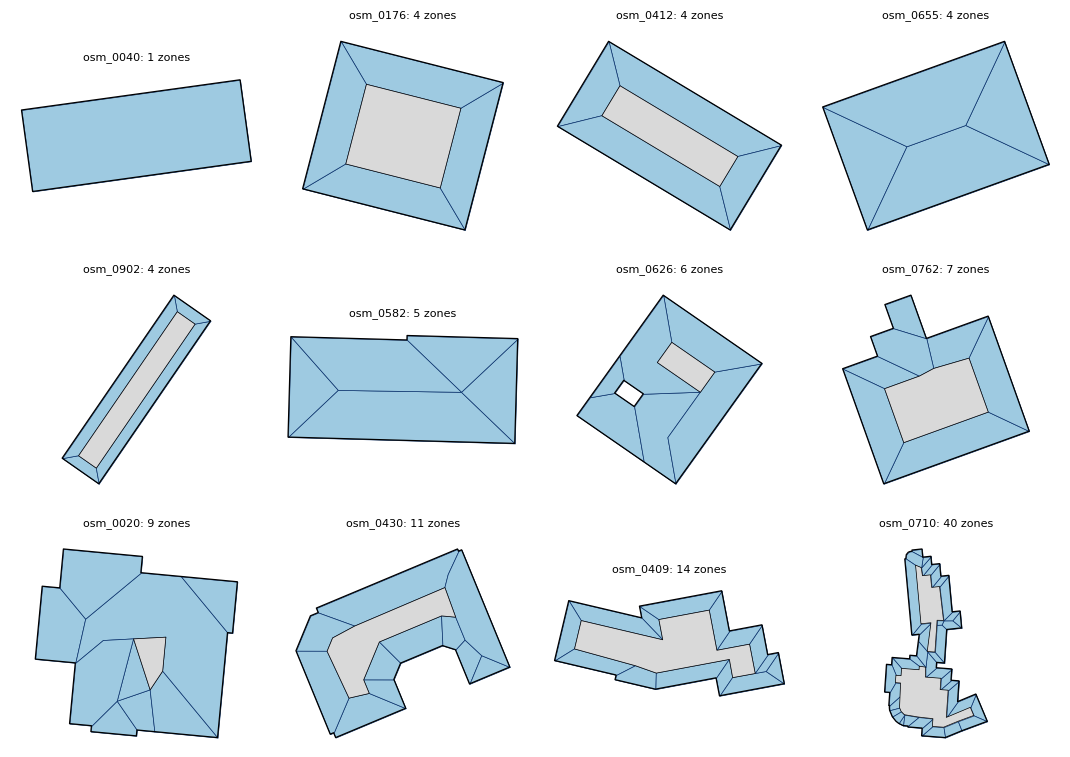

In [4]:
N_SHOW_PERIM = 12

subset_buildings_gdf = build_corner_perimeter_for_gdf(
    subset_buildings_gdf,
    geometry_col='geometry',
    config=PERIMETER_CFG,
)
perimeter_summary = summarize_corner_perimeter(subset_buildings_gdf)

print('Corner-ray perimeter summary:')
print(f"Total buildings: {perimeter_summary['n_total']}")
print(f"Perimeter zones + core: {perimeter_summary['n_with_core']}")
print(f"Perimeter zones only: {perimeter_summary['n_perimeter_only']}")
print(f"Perimeter failed (decomposed whole): {perimeter_summary['n_failed']}")
print(f"Perimeter zones: {perimeter_summary['n_perimeter_zones']}, core parts: {perimeter_summary['n_core_parts']}")
print(
    f"Zones thinner than {PERIMETER_CFG.min_zone_width_m:g} m: {perimeter_summary['n_thin_zones']} "
    f"in {perimeter_summary['n_buildings_with_thin_zones']} buildings"
)
print(
    f"Zones not convex: {perimeter_summary['n_not_convex_zones']} "
    f"in {perimeter_summary['n_buildings_with_not_convex_zones']} buildings"
)
print(
    f"Time: {perimeter_summary['seconds_total']:.1f} s in total, "
    f"at most {perimeter_summary['seconds_max']:.2f} s for one building"
)

outcomes = pd.Series({
    'perimeter zones + core': perimeter_summary['n_with_core'],
    'perimeter zones only': perimeter_summary['n_perimeter_only'],
    'perimeter failed': perimeter_summary['n_failed'],
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(outcomes.index, outcomes.values, color=['#1f77b4', '#9ecae1', '#d9d9d9'], edgecolor='black')
axes[0].set_title('Corner-ray perimeter outcomes')
axes[0].set_ylabel('count')
axes[0].tick_params(axis='x', rotation=18)

axes[1].hist(subset_buildings_gdf['n_perimeter_zones'], bins=30, color='#1f77b4', edgecolor='black')
axes[1].set_title('Perimeter zones per building')
axes[1].set_xlabel('perimeter zones')
axes[1].set_ylabel('count')

plt.tight_layout()
plt.show()

zoned = subset_buildings_gdf.loc[subset_buildings_gdf['perimeter_defined']].sort_values(['n_perimeter_zones', 'sample_id'])
perim_ids = (
    zoned['sample_id'].iloc[np.linspace(0, len(zoned) - 1, min(N_SHOW_PERIM, len(zoned))).astype(int)].tolist()
    if len(zoned) else []
)

if not perim_ids:
    print('No building was zoned by the corner-ray perimeter.')
else:
    bsub = gpd.GeoDataFrame(
        subset_buildings_gdf.loc[subset_buildings_gdf['sample_id'].isin(perim_ids)].copy(),
        geometry='geometry',
        crs=subset_buildings_gdf.crs,
    )
    for role, column in (('perimeter_zone', 'zone_parts'), ('thin_zone', 'thin_parts')):
        bsub[column] = [
            [part for part, r in zip(parts, roles) if r == role]
            for parts, roles in zip(bsub['perimeter_parts'], bsub['perimeter_part_roles'])
        ]
    bsub_core = gpd.GeoDataFrame(
        bsub.loc[bsub['interior_geom'].notna()].copy(),
        geometry='interior_geom',
        crs=subset_buildings_gdf.crs,
    )
    n_zones = bsub.set_index('sample_id')['n_perimeter_zones']

    GHSL_gridplot(
        [
            {
                'name': 'perimeter_zones',
                'gdf': bsub,
                'role': 'main',
                'id_col': 'sample_id',
                'parts_col': 'zone_parts',
                'cmap': ListedColormap(['#9ecae1']),
                'edgecolor': '#08306b',
                'linewidth': 0.5,
                'zorder': 2,
            },
            {
                'name': 'thin_zones',
                'gdf': bsub,
                'role': 'main',
                'id_col': 'sample_id',
                'parts_col': 'thin_parts',
                'cmap': ListedColormap(['#fcbba1']),
                'edgecolor': '#cb181d',
                'linewidth': 0.5,
                'zorder': 2,
            },
            {
                'name': 'core',
                'gdf': bsub_core,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'interior_geom',
                'color': '#d9d9d9',
                'edgecolor': 'black',
                'linewidth': 0.5,
                'zorder': 2,
            },
            {
                'name': 'building_outline',
                'gdf': bsub,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'geometry',
                'color': 'none',
                'edgecolor': 'black',
                'linewidth': 0.9,
                'zorder': 3,
            },
        ],
        ids=perim_ids,
        ncols=4,
        figsize_scale=2.7,
        title_fn=lambda sid, i: f'{sid}: {int(n_zones[sid])} zones',
    )

## Decompose the zones into convex parts

Every zone and core part goes to the convex-decomposition engine (`decompose_polygon_with_stats`); a convex one comes back as one part.

- **Cuts**: at a reflex corner (an inward corner) the engine offers three cuts, each running to the first boundary point it meets: either of the corner's two edges carried on, and the bisector of the corner. A courtyard is opened by two cuts from its corners to the outer wall. Every cut splits a piece into exactly two pieces whose areas add up to the piece.
- **Rules**: a cut may not leave a piece under 2 m² (`min_area_m2`) or create a corner under 30° (`min_corner_deg`, relaxed for a piece where no cut passes), and no finished zone may be thinner than 1.2 m (`min_zone_width_m`, never relaxed).
- **Score** (lower is better): the number of zones plus 20 × (1 − mean Polsby–Popper compactness of the zones), every zone counting the same. While the search runs, unfinished states are ranked by the same score with the mean weighted by area.
- **Search**: a beam search over states, each a list of pieces. Each step cuts the largest non-convex piece of the best state at up to 8 of its reflex corners, those closest to 90° first; the beam keeps the best states and parks the others. The adaptive budget starts at depth 4 and beam width 3 and grows up to depth 24 and width 4 only while no fully convex variant has been found. The search stops after 32 variants or 500 dead ends and returns the variant with the lowest score.
- **Merge fallback** (`FALLBACK = 'merge'`): when the engine cannot cut a piece of a building, the piece is merged with a neighbouring piece (longest shared edge first) and the union decomposed (role `merged_zone`); when no merge works within half the building's area, the whole footprint is decomposed (role `footprint`); when that fails too, the building stays without a decomposition.

### Prepare the decomposition inputs

**Inputs**: `subset_buildings_gdf` with the corner-ray perimeter.

**Steps**
1. List each building's polygons: its perimeter zones (`perimeter_parts`) and core parts (`interior_geom`), or the whole footprint where the perimeter failed.
2. Record each polygon's role in `decomp_polygon_roles`: `perimeter_zone`, `thin_zone`, `interior` or `footprint`.
3. Count the polygons and vertices per building and the polygons per role.

**Outputs**: `buildings_convex_gdf` with `decomp_polygons`, `decomp_polygon_roles`, `n_polygons` and `n_vertices`.

**Used functions**: `prepare_decomposition_inputs`

In [5]:
buildings_convex_gdf, *_ = prepare_decomposition_inputs(subset_buildings_gdf)

print('Buildings prepared for decomposition:', len(buildings_convex_gdf))
print('Buildings with perimeter zones + core:', int(buildings_convex_gdf['perimeter'].fillna(False).sum()))
print('Buildings with perimeter zones only:', int(buildings_convex_gdf['perimeter_only'].fillna(False).sum()))
print('Buildings decomposed whole (perimeter failed):', int((~buildings_convex_gdf['perimeter_defined'].fillna(False)).sum()))
print(f"Mean decomposition input polygons per building: {buildings_convex_gdf['n_polygons'].mean():.2f}")
print(f"Mean decomposition input vertices per building: {buildings_convex_gdf['n_vertices'].mean():.2f}")
print('')
print('Decomposition input polygons by role:')
print(buildings_convex_gdf['decomp_polygon_roles'].explode().value_counts().to_string())

Buildings prepared for decomposition: 990
Buildings with perimeter zones + core: 626
Buildings with perimeter zones only: 364
Buildings decomposed whole (perimeter failed): 0
Mean decomposition input polygons per building: 8.11
Mean decomposition input vertices per building: 36.45

Decomposition input polygons by role:
decomp_polygon_roles
perimeter_zone    7231
interior           689
thin_zone          107


### Configure the convex decomposer
`cfg` holds the search budget described above (depth 24 and width 4, adaptive from depth 4 and width 3, 8 reflex corners per piece, 32 variants, 500 dead ends), the smallest piece of 2 m² and the score weights; the corner and width rules keep the engine's defaults (30°, 1.2 m).

In [6]:
cfg = ConvexDecompositionConfig(
    search_depth=24,
    search_width=4,
    max_reflex_per_node=8,
    max_variants_per_polygon=32,
    max_failed_states=500,
    track_time=True,
    min_area_m2=2.0,
    weight_parts=1.0,
    weight_compactness=20.0,
    adaptive_search=AdaptiveSearchConfig(
        enabled=True,
        initial_depth=4,
        initial_width=3,
        max_depth=24,
        max_width=4,
        depth_step=1,
        width_step=1,
    ),
)

cfg

ConvexDecompositionConfig(search_depth=24, search_width=4, max_variants_per_polygon=32, max_failed_states=500, min_area_m2=2.0, weight_parts=1.0, weight_compactness=20.0, area_weighting=0.0, beam_area_weighting=1.0, weight_narrow=0.0, narrow_width_m=2.0, min_concavity_deg=2.0, max_reflex_per_node=8, track_time=True, use_bisector_dead_end_fallback=True, cut_snap_vertex_tolerance_m=0.1, adaptive_search=AdaptiveSearchConfig(enabled=True, initial_depth=4, initial_width=3, max_depth=24, max_width=4, depth_step=1, width_step=1), score_fn=None, beam_ranking='score_first', bisector_always=True, min_corner_deg=30.0, min_zone_width_m=1.2)

### Run the convex decomposition

**Inputs**
- `buildings_convex_gdf` with `decomp_polygons` and `decomp_polygon_roles`
- `cfg` and `FALLBACK`

**Steps**
1. Decompose every polygon of every building with `cfg`.
2. For a building with a polygon the engine cannot cut, apply the merge fallback described above.
3. Collect the convex parts, timings, search diagnostics and success flags per polygon and per building.
4. Store all convex parts of a building in `convex_parts_geom`.

**Outputs**
- `buildings_convex_gdf` with the results per building, among them `building_fully_convex`, `fallback_applied` (`'merge'`, `'whole'` or empty), `n_fallback_merges` and `fallback_seconds` (time of the searches whose result was discarded)
- `polygon_results_gdf` with one row per final polygon: its `zone_id`, `zone_role`, convex parts (`best_variant_parts`) and search diagnostics; a merged zone lists its source zones in `merged_from`
- `results_df` with the per-building results alone

**Used functions**: `run_building_decomposition`

In [7]:
# 'merge': merge a piece the engine cannot cut with a neighbour, else decompose the whole footprint; 'none': leave the building failed.
FALLBACK = 'merge'

buildings_convex_gdf, results_df, polygon_results_gdf = run_building_decomposition(
    buildings_convex_gdf, cfg, fallback=FALLBACK
)
buildings_convex_gdf.head()

,sample_id,geometry,area_m2,n_vertices,n_holes,perimeter_defined,perimeter,perimeter_only,perimeter_reason,perimeter_parts,...,n_small_zone_polygons,n_retried_polygons,total_search_attempts,max_search_depth_used,max_search_width_used,time_total_seconds,fallback_applied,n_fallback_merges,fallback_seconds,final_polygon_roles
0,osm_0001,"POLYGON ((-12.41605 16.6122, -21.49154 -11.819...",798.976977,40,0,True,True,False,perimeter_with_core,[POLYGON ((-21.491543096891686 -11.81951251042...,...,0,0,1,4,3,0.009368,NaN,0,0.0,"[perimeter_zone, perimeter_zone, perimeter_zon..."
1,osm_0002,"POLYGON ((12.28994 6.32204, -11.59102 7.25023,...",322.645924,20,0,True,True,False,perimeter_with_core,[POLYGON ((-11.59101653482482 7.25023405899659...,...,0,0,0,0,0,0.000642,NaN,0,0.0,"[perimeter_zone, perimeter_zone, perimeter_zon..."
2,osm_0003,"POLYGON ((-0.82384 8.03956, -3.24963 7.81827, ...",65.678814,16,0,True,False,True,perimeter_only_no_core,[POLYGON ((-2.509314479028198 -0.3716508108380...,...,0,0,0,0,0,0.000496,NaN,0,0.0,"[perimeter_zone, perimeter_zone, perimeter_zon..."
3,osm_0004,"POLYGON ((-1.88387 12.23407, -11.32992 1.2022,...",279.231285,28,0,True,True,False,perimeter_with_core,[POLYGON ((-11.329923145111373 1.2022009447800...,...,0,0,0,0,0,0.000847,NaN,0,0.0,"[perimeter_zone, perimeter_zone, perimeter_zon..."
4,osm_0005,"POLYGON ((6.55719 1.47794, -1.59178 5.79687, -...",74.684207,12,0,True,False,True,perimeter_only_no_core,[POLYGON ((-1.5917774614970694 5.7968684460048...,...,0,0,0,0,0,0.000394,NaN,0,0.0,"[perimeter_zone, perimeter_zone, perimeter_zon..."


### Check that no area went missing

Every stage must hand on the footprint's full area: the perimeter zones and core, the polygons handed to the decomposer, and the convex parts. Each building carries one error per stage (`perimeter_area_error_m2`, `inputs_area_error_m2`, `parts_area_error_m2`, all against the footprint); the check stops the notebook when any of them exceeds a millionth of the footprint's area. A building without a decomposition has no parts to check.

**Inputs**: `buildings_convex_gdf`.

**Outputs**: the largest error of the fully convex buildings; the notebook stops here if a building changed area.

**Used functions**: `check_area_conservation`

In [8]:
from convexdecomp.osm.diagnostics import check_area_conservation

check_area_conservation(buildings_convex_gdf)

n_checked = int(buildings_convex_gdf['building_fully_convex'].fillna(False).sum())
largest = buildings_convex_gdf['parts_area_error_m2'].abs().max()
print(f'Area kept at every stage for all {n_checked} fully convex buildings (largest error {largest:.1e} m^2).')

Area kept at every stage for all 988 fully convex buildings (largest error 9.1e-13 m^2).


## Inspect the results

### Summarize the decomposition

**Inputs**: `buildings_convex_gdf`.

**Steps**
1. Count the polygons and the buildings that are fully convex, and the buildings with a failed polygon.
2. Count the buildings with a convex part smaller than `cfg.min_area_m2`.
3. Report the convex parts per building, the search attempts, the largest depth and width the search used, and the time per building.
4. Count the buildings the merge fallback rescued, by merging or by the whole footprint, and the time of the discarded searches.

**Outputs**: printed summary.

**Used functions**: `summarize_building_decomposition`

In [9]:
summary = summarize_building_decomposition(buildings_convex_gdf, min_area_m2=cfg.min_area_m2)

print('=== Convex decomposition summary ===')
print(f"Buildings in working set: {int(summary['n_buildings_total'])}")
print(f"Polygons across all buildings: {int(summary['n_polygons_total'])}")
print(f"Polygons with fully convex decomposition: {int(summary['n_polygons_success'])} ({100.0 * int(summary['n_polygons_success']) / max(int(summary['n_polygons_total']), 1):.1f}%)")
print(f"Buildings with all polygons fully convex: {int(summary['n_buildings_success'])} ({100.0 * int(summary['n_buildings_success']) / max(int(summary['n_buildings_total']), 1):.1f}%)")
print(f"Buildings with at least one failed polygon decomposition: {int(summary['n_buildings_failed'])} ({100.0 * int(summary['n_buildings_failed']) / max(int(summary['n_buildings_total']), 1):.1f}%)")
print(f"Buildings with any zone smaller than {cfg.min_area_m2:.1f} m²: {int(summary['n_small_zone'])} ({100.0 * int(summary['n_small_zone']) / max(int(summary['n_buildings_total']), 1):.1f}%)")
print(f"Polygons that needed at least one retry: {int(summary['n_polygons_retried'])} ({100.0 * int(summary['n_polygons_retried']) / max(int(summary['n_polygons_total']), 1):.1f}%)")
print(f"Mean convex parts per building: {float(summary['parts_per_building_mean']):.2f}")
print(f"Median convex parts per building: {float(summary['parts_per_building_median']):.2f}")
print(f"Mean search attempts per polygon: {float(summary['mean_attempts_per_polygon']):.2f}")
print(f"Max selected search depth: {int(summary['max_search_depth_used'])}")
print(f"Max selected search width: {int(summary['max_search_width_used'])}")
print(f"Mean decomposition time per building: {float(summary['mean_time_seconds']):.4f} s")

fallback_counts = buildings_convex_gdf['fallback_applied'].value_counts()
print('')
print(f"Fallback '{FALLBACK}': rescued by merging {int(fallback_counts.get('merge', 0))} buildings "
      f"({int(buildings_convex_gdf['n_fallback_merges'].sum())} merges), by the whole footprint {int(fallback_counts.get('whole', 0))}; "
      f"still failed: {int((~buildings_convex_gdf['building_fully_convex'].fillna(False)).sum())}")
print(f"Time of the searches whose result was discarded: {float(buildings_convex_gdf['fallback_seconds'].sum()):.1f} s")

=== Convex decomposition summary ===
Buildings in working set: 990
Polygons across all buildings: 7951
Polygons with fully convex decomposition: 7947 (99.9%)
Buildings with all polygons fully convex: 988 (99.8%)
Buildings with at least one failed polygon decomposition: 2 (0.2%)
Buildings with any zone smaller than 2.0 m²: 9 (0.9%)
Polygons that needed at least one retry: 30 (0.4%)
Mean convex parts per building: 9.18
Median convex parts per building: 7.00
Mean search attempts per polygon: 0.12
Max selected search depth: 24
Max selected search width: 13
Mean decomposition time per building: 0.4322 s

Fallback 'merge': rescued by merging 67 buildings (76 merges), by the whole footprint 0; still failed: 2
Time of the searches whose result was discarded: 418.5 s


### Draw buildings rescued by the merge fallback

**Inputs**: `buildings_convex_gdf` with `fallback_applied` and `n_fallback_merges`; `polygon_results_gdf` with the merged zones.

**Steps**
1. Select the rescued buildings with the most merges.
2. Draw each building's zones with the zones that were merged in red, and next to them its convex parts with each merged zone outlined in dark blue.

**Outputs**: one figure, one row per building.

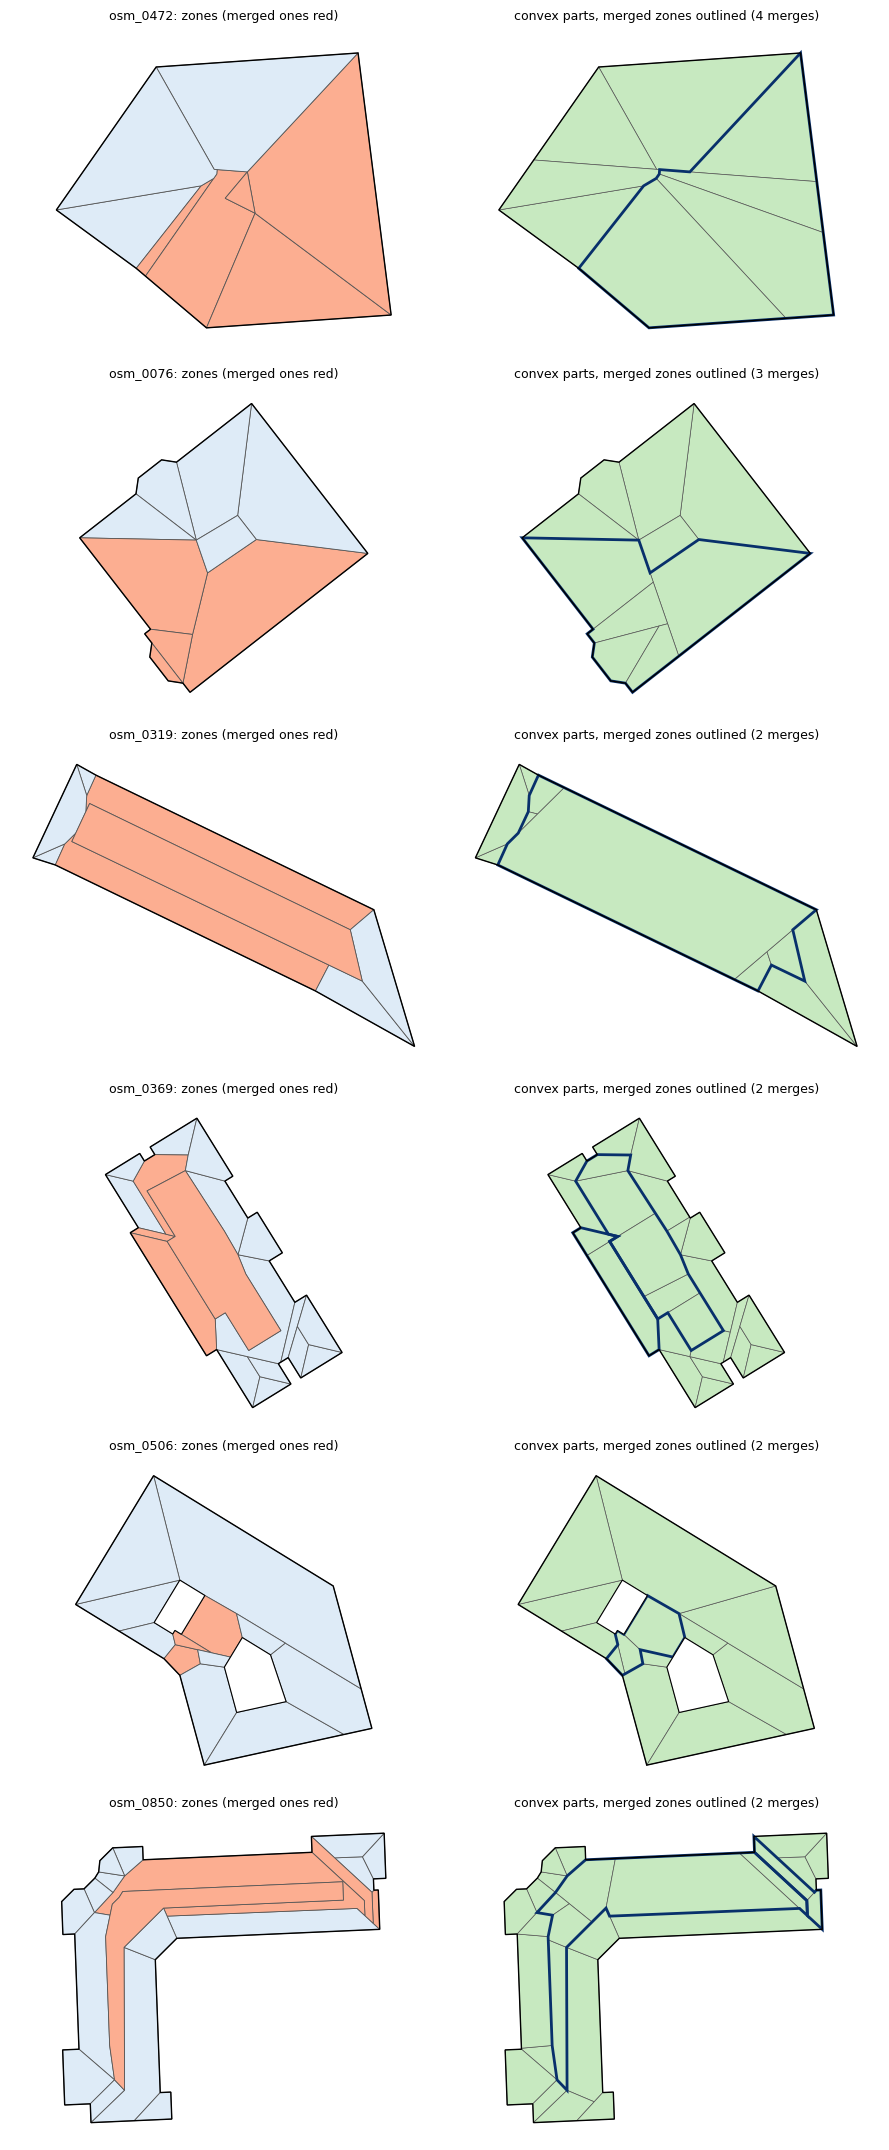

In [10]:
N_RESCUED = 6

rescued = buildings_convex_gdf.loc[buildings_convex_gdf['fallback_applied'].eq('merge')]
rescued = rescued.sort_values(['n_fallback_merges', 'sample_id'], ascending=[False, True]).head(N_RESCUED)
if rescued.empty:
    print('No building needed the merge fallback.')
else:
    merged_rows = polygon_results_gdf.loc[polygon_results_gdf['zone_role'].eq('merged_zone')]
    fig, axes = plt.subplots(len(rescued), 2, figsize=(9, 3.6 * len(rescued)), squeeze=False)
    for (ax_zones, ax_parts), (_, building) in zip(axes, rescued.iterrows()):
        merged = merged_rows.loc[merged_rows['sample_id'].eq(building['sample_id'])]
        merged_from = {zone_id for zone_ids in merged['merged_from'] for zone_id in zone_ids}
        for k, zone in enumerate(building['decomp_polygons'], start=1):
            in_merge = f"{building['sample_id']}_poly_{k:02d}" in merged_from
            fill_polygon_geometry(ax_zones, zone, facecolor='#fcae91' if in_merge else '#deebf7',
                                  edgecolor='#555555', linewidth=0.6)
        for part in parts_from_geom(building['convex_parts_geom']):
            fill_polygon_geometry(ax_parts, part, facecolor='#c7e9c0', edgecolor='#555555', linewidth=0.5)
        for zone in merged.geometry:
            fill_polygon_geometry(ax_parts, zone, facecolor='none', edgecolor='#08306b', linewidth=2.0)
        for ax in (ax_zones, ax_parts):
            fill_polygon_geometry(ax, building['geometry'], facecolor='none', edgecolor='black', linewidth=1.0)
            set_geometry_frame(ax, building['geometry'], min_pad=1.0, pad_ratio=0.06, hide_ticks=True)
        ax_zones.set_title(f"{building['sample_id']}: zones (merged ones red)", fontsize=9)
        ax_parts.set_title(f"convex parts, merged zones outlined ({int(building['n_fallback_merges'])} merges)", fontsize=9)
    plt.tight_layout()
    plt.show()

### Summarize failure reasons, engine fallbacks and retries

`fallback_used` names the engine's own fallback inside one search: `sharp_corner` (the 30° corner rule relaxed for a piece where no cut passed it), `bisector_dead_end` (the bisector at a corner where no edge cut passed), `diagonal_no_reflex` (a cut between two vertices where no usable reflex corner was left) or `hole_edge_split` (a courtyard split along its edges where no pair of chords opened it). The merge fallback of the building is recorded in `fallback_applied` of `buildings_convex_gdf`.

**Inputs**: `polygon_results_gdf`.

**Steps**
1. Classify the polygons without a decomposition by their dead-end counters (`failure_reason`).
2. Count the engine fallbacks, the search attempts per polygon and the depths and widths the search ended with.
3. List the buildings with the most failed polygons and with the most polygons holding a part under 2 m².

**Outputs**: `polygon_results_gdf` with `failure_reason`, `failed_polygon_gdf` and `small_zone_polygon_gdf`; printed counts.

**Used functions**: `annotate_polygon_failure_reasons`

In [11]:
polygon_results_gdf, failed_polygon_gdf, small_zone_polygon_gdf = annotate_polygon_failure_reasons(polygon_results_gdf)

print('=== Polygon-level decomposition diagnostics ===')
print(f'Total polygons: {len(polygon_results_gdf)}')
print(f'Failed polygons: {len(failed_polygon_gdf)}')
print(f'Small-zone polygons: {len(small_zone_polygon_gdf)}')
print('')
print('Fallback usage:')
print(polygon_results_gdf['fallback_used'].fillna('none').value_counts().to_string())
print('')
print('Adaptive search attempts per polygon:')
print(polygon_results_gdf['search_attempt_count'].fillna(0).astype(int).value_counts().sort_index().to_string())
print('')
print('Selected search depths:')
used_depths = polygon_results_gdf['search_depth_used'].dropna()
print(used_depths.astype(int).value_counts().sort_index().to_string() if not used_depths.empty else 'None')
print('')
print('Selected search widths:')
used_widths = polygon_results_gdf['search_width_used'].dropna()
print(used_widths.astype(int).value_counts().sort_index().to_string() if not used_widths.empty else 'None')
print('')
print('Failure reasons:')
print(failed_polygon_gdf['failure_reason'].value_counts().to_string() if not failed_polygon_gdf.empty else 'None')
print('')
print('Search stop reasons for failed polygons:')
print(failed_polygon_gdf['search_terminated_by'].fillna('missing').value_counts().to_string() if not failed_polygon_gdf.empty else 'None')
print('')
print('Most common failed polygons:')
print(failed_polygon_gdf['sample_id'].value_counts().head(10).to_string() if not failed_polygon_gdf.empty else 'None')
print('')
print('Most common small-zone polygons:')
print(small_zone_polygon_gdf['sample_id'].value_counts().head(10).to_string() if not small_zone_polygon_gdf.empty else 'None')
print('')

=== Polygon-level decomposition diagnostics ===
Total polygons: 7951
Failed polygons: 4
Small-zone polygons: 10

Fallback usage:
fallback_used
none                  7926
sharp_corner            18
diagonal_no_reflex       7

Adaptive search attempts per polygon:
search_attempt_count
0     7113
1      808
2       14
3        5
4        4
5        3
6        1
9        1
11       1
16       1

Selected search depths:
search_depth_used
4     806
5      13
6       4
7       4
8       3
9       1
14      1
24      6

Selected search widths:
search_width_used
3     832
4       4
9       1
13      1

Failure reasons:
failure_reason
thinner_than_min_zone_width    2
queue_exhausted                1
min_area_dead_ends             1

Search stop reasons for failed polygons:
search_terminated_by
thinner_than_min_zone_width    2
queue_exhausted                2

Most common failed polygons:
sample_id
osm_0719    3
osm_0517    1

Most common small-zone polygons:
sample_id
osm_0565    2
osm_0034    1

### Draw failed and small-zone polygons
Draws the polygons without a decomposition (orange, inside their building's outline) and the polygons with a convex part under `cfg.min_area_m2` (that part red, the others blue).

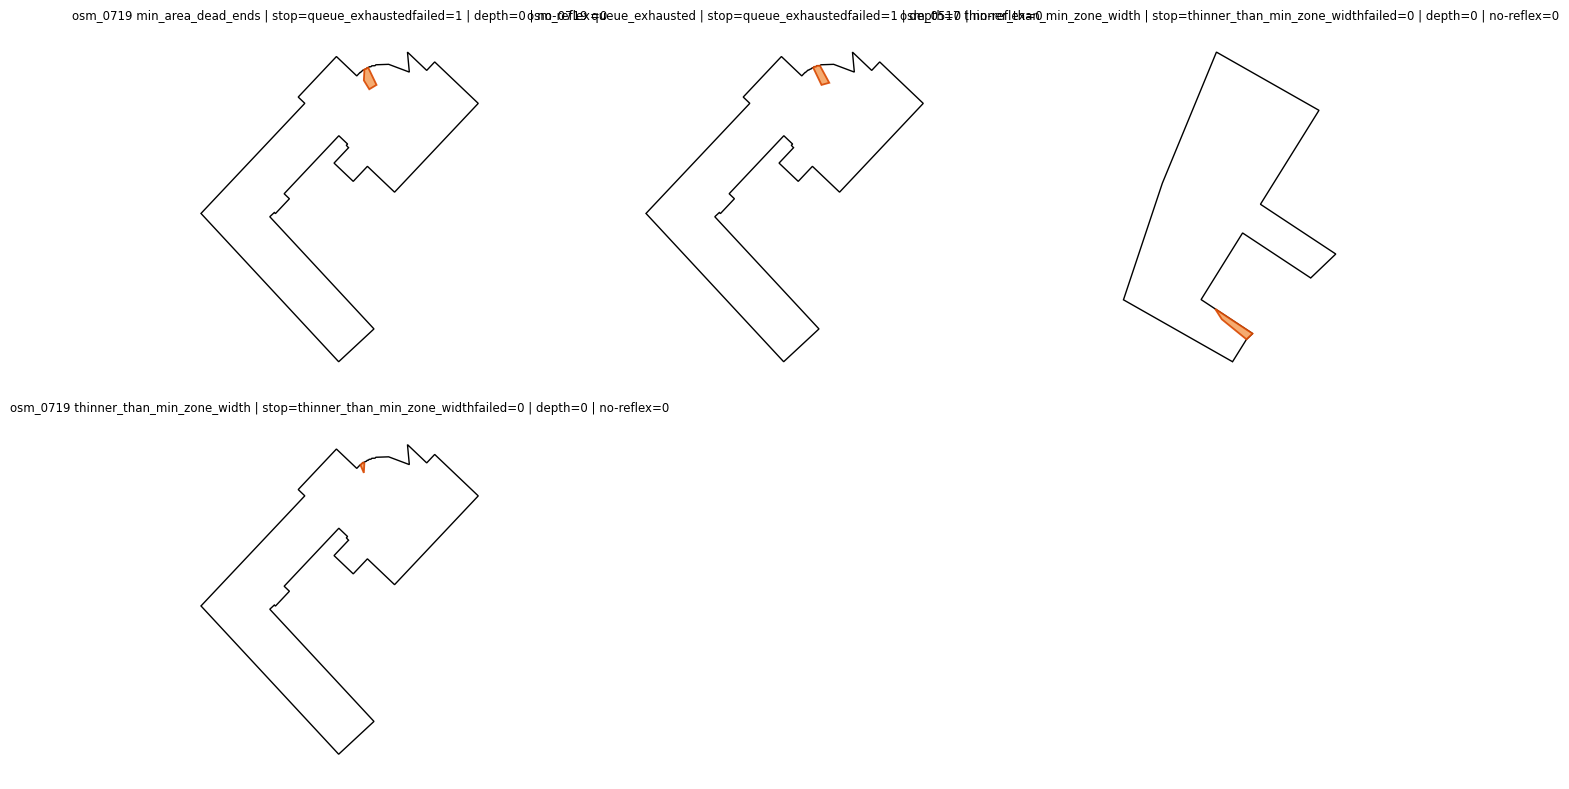

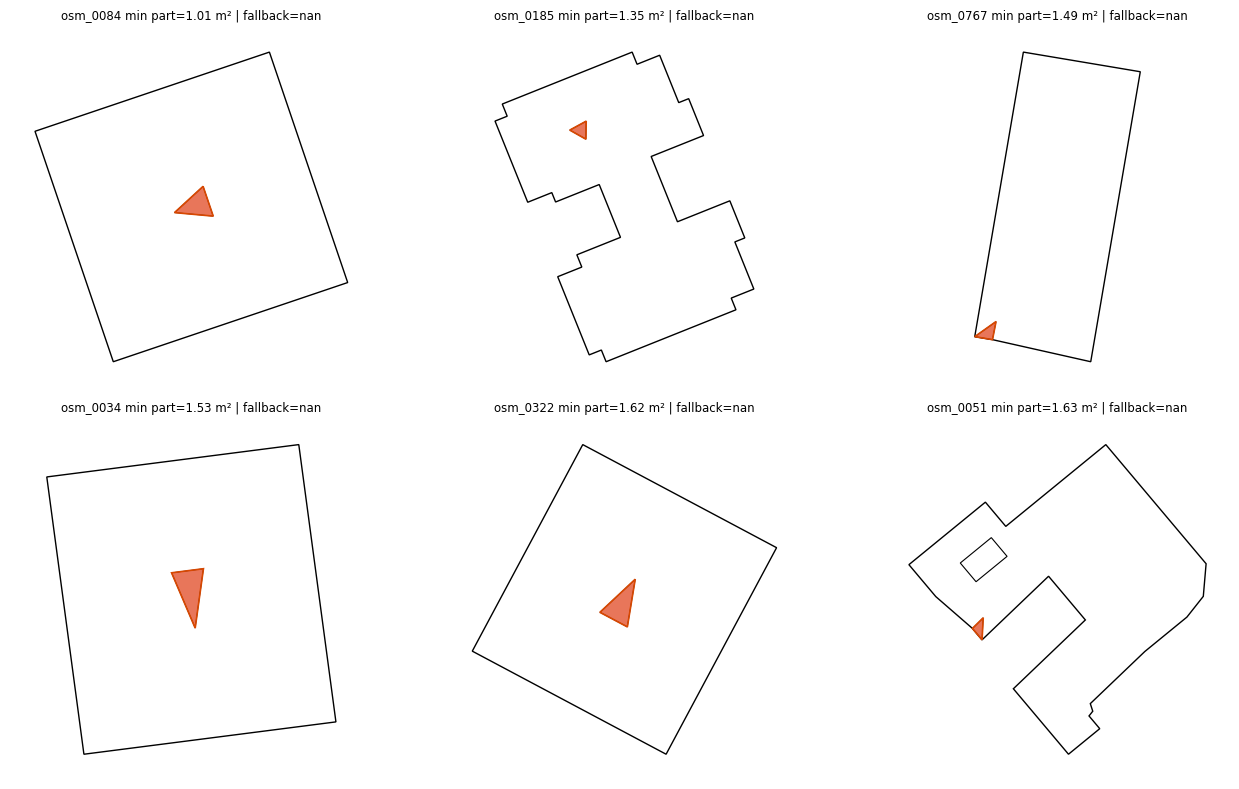

In [12]:
N_FAILURE_EXAMPLES = 6
N_SMALL_ZONE_EXAMPLES = 6

failed_examples = failed_polygon_gdf.sort_values(
    ['failure_reason', 'n_failed_terminal_states', 'n_states_seen'],
    ascending=[True, False, False],
).head(N_FAILURE_EXAMPLES)
small_zone_examples = small_zone_polygon_gdf.sort_values(
    ['best_min_part_area_m2', 'n_states_seen'],
    ascending=[True, False],
).head(N_SMALL_ZONE_EXAMPLES)

if failed_examples.empty:
    print('No failed polygons under the current configuration.')
else:
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8))
    axes = axes.flatten()
    for ax, (_, rec) in zip(axes, failed_examples.iterrows()):
        fill_polygon_geometry(ax, rec['building_geometry'], facecolor='none', edgecolor='black', linewidth=1.0)
        fill_polygon_geometry(ax, rec['geometry'], facecolor='#f4a261', edgecolor='#d94801', linewidth=1.3, alpha=0.9)
        set_geometry_frame(ax, rec['building_geometry'], min_pad=1.0, pad_ratio=0.08, hide_ticks=True)
        ax.set_title(
            f"{rec['sample_id']} {rec['failure_reason']} | stop={rec['search_terminated_by']}"
            f"failed={int(rec['n_failed_terminal_states'])} | depth={int(rec['n_depth_limit_dead_ends'])} | "
            f"no-reflex={int(rec['n_no_reflex_dead_ends'])}",
            fontsize=8.5,
        )
    for ax in axes[len(failed_examples):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

if small_zone_examples.empty:
    print('No small-zone polygons under the current configuration.')
else:
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8))
    axes = axes.flatten()
    for ax, (_, rec) in zip(axes, small_zone_examples.iterrows()):
        fill_polygon_geometry(ax, rec['building_geometry'], facecolor='none', edgecolor='black', linewidth=1.0)
        for part in parts_from_geom(rec['best_variant_geom']):
            area = getattr(part, 'area', 0.0)
            fill_polygon_geometry(
                ax,
                part,
                facecolor='#e76f51' if area < cfg.min_area_m2 else '#8ecae6',
                edgecolor='black',
                linewidth=0.6,
                alpha=0.95,
            )
        fill_polygon_geometry(ax, rec['geometry'], facecolor='none', edgecolor='#d94801', linewidth=1.2)
        set_geometry_frame(ax, rec['building_geometry'], min_pad=1.0, pad_ratio=0.08, hide_ticks=True)
        ax.set_title(
            f"{rec['sample_id']} min part={rec['best_min_part_area_m2']:.2f} m² | fallback={rec['fallback_used'] or 'none'}",
            fontsize=8.5,
        )
    for ax in axes[len(small_zone_examples):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### Plot convex part counts
The convex parts per building and the largest number of parts any one polygon of a building was cut into.

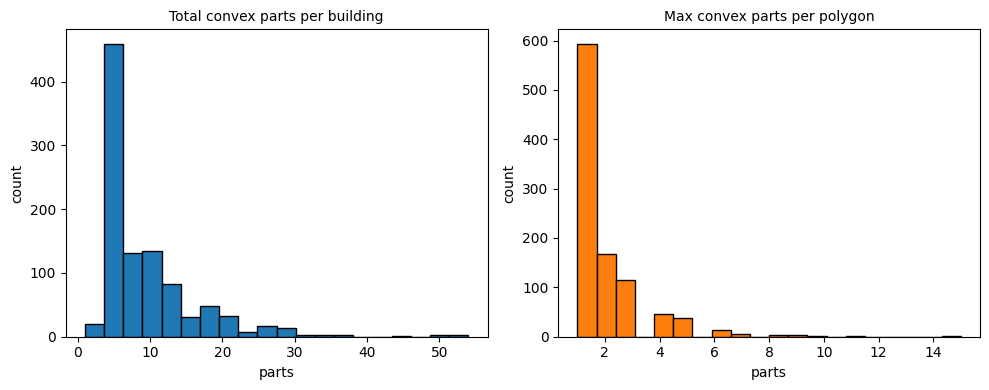

In [13]:
total_parts = buildings_convex_gdf['convex_parts_counts'].apply(lambda xs: int(sum(xs)) if isinstance(xs, list) else 0)
max_parts = buildings_convex_gdf['convex_parts_counts'].apply(lambda xs: int(max(xs)) if isinstance(xs, list) and xs else 0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(total_parts, bins=20, color='#1f77b4', edgecolor='black')
axes[0].set_title('Total convex parts per building')
axes[0].set_xlabel('parts')
axes[0].set_ylabel('count')

axes[1].hist(max_parts, bins=20, color='#ff7f0e', edgecolor='black')
axes[1].set_title('Max convex parts per polygon')
axes[1].set_xlabel('parts')
axes[1].set_ylabel('count')

plt.tight_layout()
plt.show()

### Plot success and runtime by vertex count
The share of fully convex polygons and the mean decomposition time per building against the footprint's vertex count, for buildings with perimeter zones only and with perimeter zones and a core.

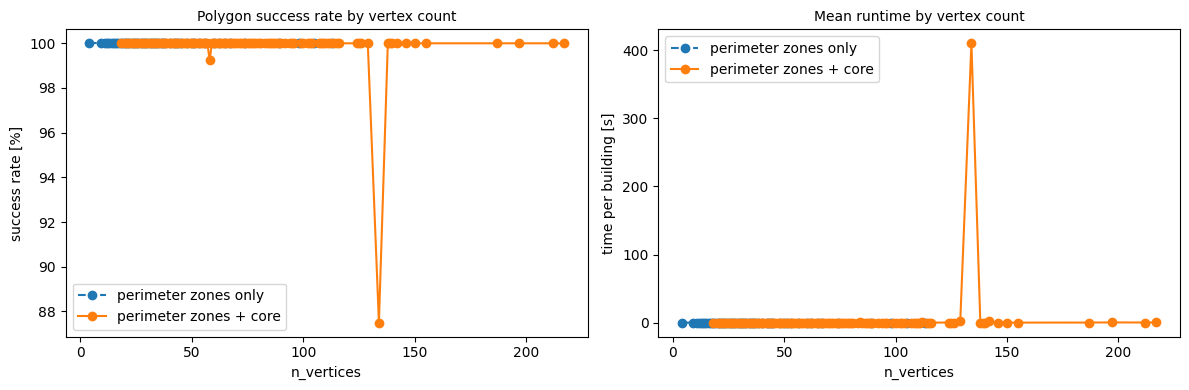

In [14]:
stats_plot_df = buildings_convex_gdf.copy()
stats_plot_df['perimeter_bool'] = stats_plot_df['perimeter'].fillna(False).astype(bool)
stats_plot_df['polygon_success_rate'] = stats_plot_df['polygon_fully_convex_flags'].apply(
    lambda flags: (sum(flags) / len(flags)) if isinstance(flags, list) and flags else np.nan
)

grouped = (
    stats_plot_df
    .groupby(['n_vertices', 'perimeter_bool'])[['polygon_success_rate', 'time_total_seconds']]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

for is_perimeter, linestyle, label in [(False, '--', 'perimeter zones only'), (True, '-', 'perimeter zones + core')]:
    sub = grouped.loc[grouped['perimeter_bool'] == is_perimeter].sort_values('n_vertices')
    if sub.empty:
        continue
    axes[0].plot(sub['n_vertices'], 100.0 * sub['polygon_success_rate'], linestyle=linestyle, marker='o', label=label)
    axes[1].plot(sub['n_vertices'], sub['time_total_seconds'], linestyle=linestyle, marker='o', label=label)

axes[0].set_title('Polygon success rate by vertex count')
axes[0].set_xlabel('n_vertices')
axes[0].set_ylabel('success rate [%]')
axes[0].legend()

axes[1].set_title('Mean runtime by vertex count')
axes[1].set_xlabel('n_vertices')
axes[1].set_ylabel('time per building [s]')
axes[1].legend()

plt.tight_layout()
plt.show()

### Compare footprints with their convex parts

**Inputs**: `buildings_convex_gdf`.

**Steps**
1. Select up to 16 buildings with perimeter zones only and 16 with perimeter zones and a core, across the vertex range (`select_complexity_ids`).
2. Draw four rows: the outlines and the convex parts of the buildings without a core, then the perimeter band (dark blue) and core (light blue) and the convex parts of the buildings with a core.
3. Save each row as a PDF in `EXPORT_DIR`.

**Outputs**: four figures and their PDFs in `tmp/osm_2_decomposition_exports/`.

**Used functions**: `select_complexity_ids`, `parts_from_geom`, `GHSL_gridplot`

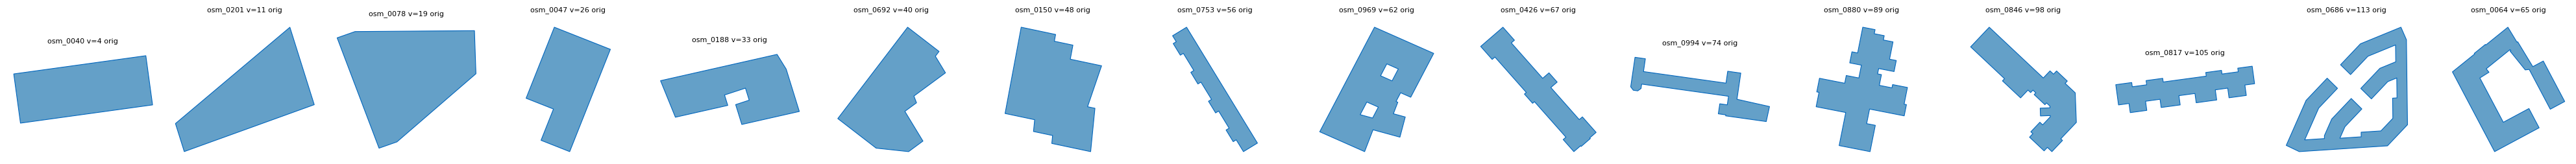

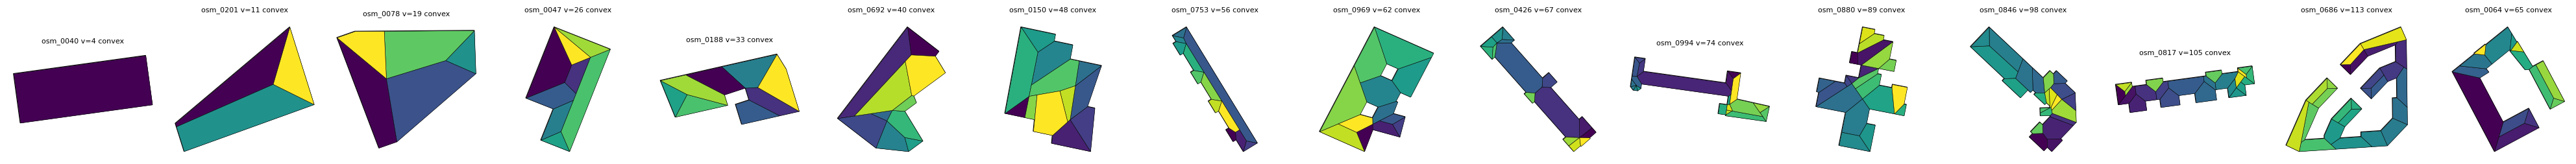

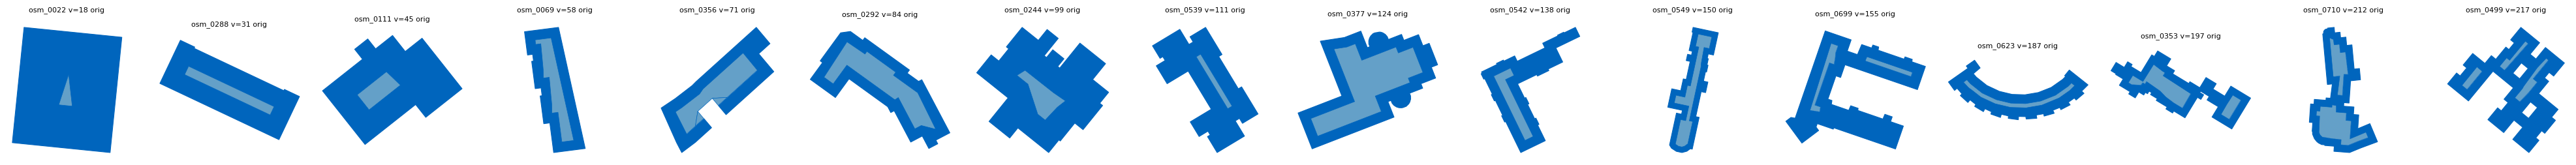

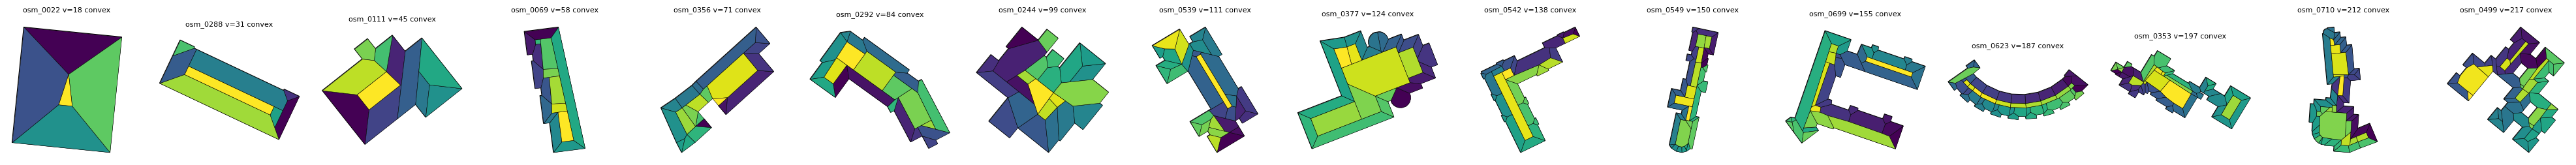

In [15]:
TUM_DARK = '#0065BD'
TUM_LIGHT = '#64A0C8'
N_COMPARE = 16
EXPORT_DIR = PROJECT_ROOT / 'tmp' / 'osm_2_decomposition_exports'
EXPORT_DIR.mkdir(parents=True, exist_ok=True)


def save_current_grid_pdf(stem: str) -> None:
    fig = plt.gcf()
    fig.savefig(EXPORT_DIR / f'{stem}.pdf', bbox_inches='tight')


nonperim_ids = select_complexity_ids(buildings_convex_gdf, perimeter_flag=False, n_examples=N_COMPARE)
perim_ids_compare = select_complexity_ids(buildings_convex_gdf, perimeter_flag=True, n_examples=N_COMPARE)

nonperim = buildings_convex_gdf.loc[buildings_convex_gdf['sample_id'].isin(nonperim_ids)].copy()
nonperim['sample_id'] = nonperim['sample_id'].astype(str)
nonperim['order_idx'] = nonperim['sample_id'].map({sid: i for i, sid in enumerate(nonperim_ids)})
nonperim = nonperim.sort_values('order_idx')
nonperim_outline = gpd.GeoDataFrame(nonperim, geometry='geometry', crs=buildings_convex_gdf.crs)
nonperim_parts = nonperim.copy()
nonperim_parts['convex_parts_list'] = nonperim_parts['convex_parts_geom'].apply(parts_from_geom)
nonperim_lookup = nonperim.set_index('sample_id')

if nonperim_ids:
    GHSL_gridplot(
        [
            {
                'name': 'nonperim_original',
                'gdf': nonperim_outline,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'geometry',
                'color': TUM_LIGHT,
                'edgecolor': TUM_DARK,
                'linewidth': 0.8,
            }
        ],
        ids=nonperim_ids,
        ncols=len(nonperim_ids),
        nrows=1,
        figsize_scale=2.5,
        title_fn=lambda sid, i: f"{sid} v={int(nonperim_lookup.loc[sid, 'n_vertices'])} orig",
    )
    save_current_grid_pdf('nonperim_original_grid')
    plt.show()

    GHSL_gridplot(
        [
            {
                'name': 'nonperim_outline',
                'gdf': nonperim_outline,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'geometry',
                'color': 'none',
                'edgecolor': 'black',
                'linewidth': 0.8,
            },
            {
                'name': 'nonperim_convex_parts',
                'gdf': nonperim_parts,
                'role': 'main',
                'id_col': 'sample_id',
                'parts_col': 'convex_parts_list',
                'cmap': 'viridis',
                'edgecolor': 'black',
                'linewidth': 0.4,
            },
        ],
        ids=nonperim_ids,
        ncols=len(nonperim_ids),
        nrows=1,
        figsize_scale=2.5,
        title_fn=lambda sid, i: f"{sid} v={int(nonperim_lookup.loc[sid, 'n_vertices'])} convex",
    )
    save_current_grid_pdf('nonperim_convex_grid')
    plt.show()

perim = buildings_convex_gdf.loc[buildings_convex_gdf['sample_id'].isin(perim_ids_compare)].copy()
perim['sample_id'] = perim['sample_id'].astype(str)
perim['order_idx'] = perim['sample_id'].map({sid: i for i, sid in enumerate(perim_ids_compare)})
perim = perim.sort_values('order_idx')
perim_shell = gpd.GeoDataFrame(perim, geometry='perimeter_geom', crs=buildings_convex_gdf.crs)
perim_interior = gpd.GeoDataFrame(perim.loc[perim['interior_geom'].notna()].copy(), geometry='interior_geom', crs=buildings_convex_gdf.crs)
perim_parts = perim.copy()
perim_parts['convex_parts_list'] = perim_parts['convex_parts_geom'].apply(parts_from_geom)
perim_lookup = perim.set_index('sample_id')

if perim_ids_compare:
    GHSL_gridplot(
        [
            {
                'name': 'perim_shell',
                'gdf': perim_shell,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'perimeter_geom',
                'color': TUM_DARK,
                'edgecolor': TUM_DARK,
                'linewidth': 0.8,
            },
            {
                'name': 'perim_interior',
                'gdf': perim_interior,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'interior_geom',
                'color': TUM_LIGHT,
                'edgecolor': TUM_DARK,
                'linewidth': 0.5,
            },
        ],
        ids=perim_ids_compare,
        ncols=len(perim_ids_compare),
        nrows=1,
        figsize_scale=2.5,
        title_fn=lambda sid, i: f"{sid} v={int(perim_lookup.loc[sid, 'n_vertices'])} orig",
    )
    save_current_grid_pdf('perim_original_grid')
    plt.show()

    GHSL_gridplot(
        [
            {
                'name': 'perim_outline',
                'gdf': perim_shell,
                'role': 'main',
                'id_col': 'sample_id',
                'geometry_col': 'perimeter_geom',
                'color': 'none',
                'edgecolor': 'black',
                'linewidth': 0.8,
            },
            {
                'name': 'perim_convex_parts',
                'gdf': perim_parts,
                'role': 'main',
                'id_col': 'sample_id',
                'parts_col': 'convex_parts_list',
                'cmap': 'viridis',
                'edgecolor': 'black',
                'linewidth': 0.4,
            },
        ],
        ids=perim_ids_compare,
        ncols=len(perim_ids_compare),
        nrows=1,
        figsize_scale=2.5,
        title_fn=lambda sid, i: f"{sid} v={int(perim_lookup.loc[sid, 'n_vertices'])} convex",
    )
    save_current_grid_pdf('perim_convex_grid')
    plt.show()

### Summarize convex coverage of the working set
The building counts of the run: buildings with a failed polygon, fully convex buildings, and fully convex buildings whose zones are all at least `cfg.min_area_m2`. `buildings_convex_gdf` keeps every building of the working set, whatever its result.

In [16]:
n_loaded = len(subset_buildings_gdf)
n_total = len(buildings_convex_gdf)

fully_convex_flags = buildings_convex_gdf['building_fully_convex'].fillna(False).astype(bool).to_numpy(dtype=bool)
failed_flags = buildings_convex_gdf['building_decomposition_failed'].fillna(False).astype(bool).to_numpy(dtype=bool)
small_zone_flags = buildings_convex_gdf['building_has_small_zone'].fillna(False).astype(bool).to_numpy(dtype=bool)
clean_convex_flags = fully_convex_flags & ~small_zone_flags

n_failed = int(np.sum(failed_flags))
n_fully_convex = int(np.sum(fully_convex_flags))
n_clean_convex = int(np.sum(clean_convex_flags))
n_small_zone = int(np.sum(small_zone_flags))

pct_failed = 100.0 * n_failed / n_total if n_total else 0.0
pct_fully_convex = 100.0 * n_fully_convex / n_total if n_total else 0.0
pct_clean_convex = 100.0 * n_clean_convex / n_total if n_total else 0.0
pct_small_zone = 100.0 * n_small_zone / n_total if n_total else 0.0
pct_retained = 100.0 * n_total / n_loaded if n_loaded else 0.0

print('=== Dataset-level pipeline summary ===')
print(f'Loaded preselected subset: {n_loaded}')
print(f'Buildings prepared for decomposition: {n_total} / {n_loaded} ({pct_retained:.1f}%)')
print(f'Buildings with at least one failed polygon decomposition: {n_failed} / {n_total} ({pct_failed:.1f}%)')
print(f'Fully convex after decomposition: {n_fully_convex} / {n_total} ({pct_fully_convex:.1f}%)')
print(
    f'Fully convex and all zones >= {cfg.min_area_m2:.1f} m^2 after decomposition: '
    f'{n_clean_convex} / {n_total} ({pct_clean_convex:.1f}%)'
)
print(f'Buildings with any zone smaller than {cfg.min_area_m2:.1f} m^2: {n_small_zone} / {n_total} ({pct_small_zone:.1f}%)')
print(
    'Retained building table with decomposition diagnostics '
    f'(no extra post-decomposition geometry filter): {n_total} / {n_loaded} ({pct_retained:.1f}%)'
)

=== Dataset-level pipeline summary ===
Loaded preselected subset: 990
Buildings prepared for decomposition: 990 / 990 (100.0%)
Buildings with at least one failed polygon decomposition: 2 / 990 (0.2%)
Fully convex after decomposition: 988 / 990 (99.8%)
Fully convex and all zones >= 2.0 m^2 after decomposition: 979 / 990 (98.9%)
Buildings with any zone smaller than 2.0 m^2: 9 / 990 (0.9%)
Retained building table with decomposition diagnostics (no extra post-decomposition geometry filter): 990 / 990 (100.0%)


## Export zone provenance and boundary interfaces

The convex parts alone cannot say which of their walls exist in reality. This step records for every part the building and the zone it came from, and classifies every boundary segment it owns. An OSM footprint is one physical envelope, so the whole building is one space and its zones are zones inside it: a wall between two zones (perimeter zones, core parts, merged zones) is a `zoning_split`, a deliberate thermal-zoning boundary; a cut of the convex decomposition inside one zone is an `artificial_split`; a wall on the footprint's outline is `exterior`. A segment without a neighbouring part that does not lie on its zone's boundary is `unmatched`: the parts do not tile their zone exactly there.

### Write the zones and interfaces

**Inputs**
- `polygon_results_gdf` with one row per zone, its polygon and its convex parts
- `OSM_DATA_DIR` as the output folder

**Steps**
1. Build one record per convex part with its chain `container -> space -> zone -> part` (building, building, zone, part).
2. Classify every boundary segment against the neighbouring parts of the same building.
3. Report the counts, including unmatched segments.
4. Write the layers `zones` and `interfaces` to `osm_zones.gpkg` in `OSM_DATA_DIR`.

**Outputs**
- `osm_parts`, `osm_interfaces` and `osm_zone_summary`
- `OSM_DATA_DIR / 'osm_zones.gpkg'`

**Used functions**: `osm_part_records`, `build_interfaces`, `summarize_interfaces`, `parts_to_geodataframe`, `interfaces_to_geodataframe`, `write_zone_artifacts`

In [17]:
from convexdecomp.zones.adapters import osm_part_records
from convexdecomp.zones.export import (
    interfaces_to_geodataframe,
    parts_to_geodataframe,
    write_zone_artifacts,
)
from convexdecomp.zones.interfaces import (
    InterfaceConfig,
    build_interfaces,
    summarize_interfaces,
)

ZONE_INTERFACE_CFG = InterfaceConfig(tol=1e-6)

osm_parts = osm_part_records(polygon_results_gdf)
osm_interfaces = build_interfaces(osm_parts, ZONE_INTERFACE_CFG)
osm_zone_summary = summarize_interfaces(osm_parts, osm_interfaces)

print('=== OSM zone provenance ===')
print(f"Convex parts: {osm_zone_summary['n_parts']}")
print(f"Source spaces (buildings): {osm_zone_summary['n_spaces']}")
print(f"Spaces split into several parts: {osm_zone_summary['n_split_spaces']}")
print(f"Boundary segments: {osm_zone_summary['n_interfaces']}")
print(f"Virtual segments (artificial + zoning): {osm_zone_summary['n_virtual_interfaces']}")
print(f"Unmatched segments: {osm_zone_summary['n_unmatched']}")
print(f"Ambiguous segments: {osm_zone_summary['n_ambiguous']}")
print('')
print('Boundary length by kind [m]:')
for kind, length in sorted(osm_zone_summary['interface_length_by_kind'].items()):
    print(f'  {kind:20s} {length:12.2f}')

if osm_zone_summary['n_unmatched']:
    unmatched_length = osm_zone_summary['interface_length_by_kind'].get('unmatched', 0.0)
    total_length = sum(osm_zone_summary['interface_length_by_kind'].values())
    print('')
    print(
        f"Note: {osm_zone_summary['n_unmatched']} segments ({100.0 * unmatched_length / total_length:.2f}% of "
        'boundary length) have no neighbouring part and do not lie on their source zone boundary. '
        'They mark places where the decomposed parts do not tile their source zone exactly. '
        'Raise ZONE_INTERFACE_CFG.tol if they are numerical, or inspect them as geometry defects.'
    )

osm_zones_gdf = parts_to_geodataframe(osm_parts, crs=buildings_convex_gdf.crs)
osm_interfaces_gdf = interfaces_to_geodataframe(osm_interfaces, crs=buildings_convex_gdf.crs)

osm_zone_paths = write_zone_artifacts(
    osm_zones_gdf,
    osm_interfaces_gdf,
    OSM_DATA_DIR / 'osm_zones.gpkg',
)
print('')
for layer, path in osm_zone_paths.items():
    print(f'Wrote layer {layer} to {Path(path).resolve().relative_to(PROJECT_ROOT)}')

=== OSM zone provenance ===
Convex parts: 9094
Source spaces (buildings): 990
Spaces split into several parts: 988
Boundary segments: 40149
Virtual segments (artificial + zoning): 30256
Unmatched segments: 0
Ambiguous segments: 0

Boundary length by kind [m]:
  artificial_split         11128.44
  exterior                 94898.29
  zoning_split            182727.80



Wrote layer zones to data/bem4ai/osm_zones.gpkg
Wrote layer interfaces to data/bem4ai/osm_zones.gpkg
